<a href="https://colab.research.google.com/github/MrdnvShafiga/Machine-Learning-/blob/main/Customer_Churn_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

In [8]:
df = pd.read_csv('/content/customer_churn_dataset-testing-master.csv')
df

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...
64369,64370,45,Female,33,12,6,21,Basic,Quarterly,947,14,1
64370,64371,37,Male,6,1,5,22,Standard,Annual,923,9,1
64371,64372,25,Male,39,14,8,30,Premium,Monthly,327,20,1
64372,64373,50,Female,18,19,7,22,Standard,Monthly,540,13,1


In [9]:
df.shape

(64374, 12)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         64374 non-null  int64 
 1   Age                64374 non-null  int64 
 2   Gender             64374 non-null  object
 3   Tenure             64374 non-null  int64 
 4   Usage Frequency    64374 non-null  int64 
 5   Support Calls      64374 non-null  int64 
 6   Payment Delay      64374 non-null  int64 
 7   Subscription Type  64374 non-null  object
 8   Contract Length    64374 non-null  object
 9   Total Spend        64374 non-null  int64 
 10  Last Interaction   64374 non-null  int64 
 11  Churn              64374 non-null  int64 
dtypes: int64(9), object(3)
memory usage: 5.9+ MB


In [11]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [12]:
df.describe(include='object')

,Gender,Subscription Type,Contract Length
count,64374,64374,64374
unique,2,3,3
top,Female,Standard,Monthly
freq,34353,21502,22130


In [13]:
df.isnull().sum()

,0
CustomerID,0
Age,0
Gender,0
Tenure,0
Usage Frequency,0
Support Calls,0
Payment Delay,0
Subscription Type,0
Contract Length,0
Total Spend,0


In [14]:
print('Dublikat sətir:', df.duplicated().sum())
print('Dublikat CustomerID:', df['CustomerID'].duplicated().sum())

Dublikat sətir: 0
Dublikat CustomerID: 0


In [15]:
df['Churn'].value_counts()

,count
Churn,
0,33881
1,30493


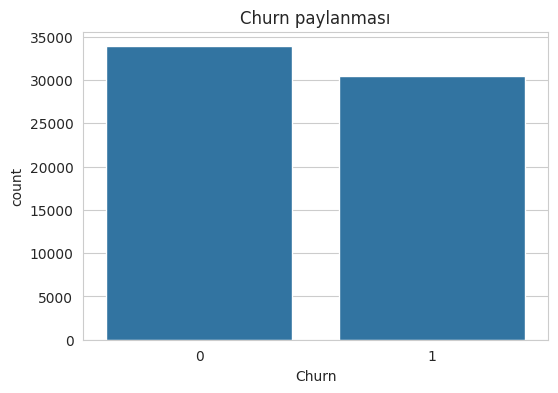

In [16]:
plt.figure(figsize=(6,4))
sns.countplot(x=df['Churn'])
plt.title('Churn paylanması')
plt.show()

In [17]:
num_cols = ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
cat_cols = ['Gender', 'Subscription Type', 'Contract Length']

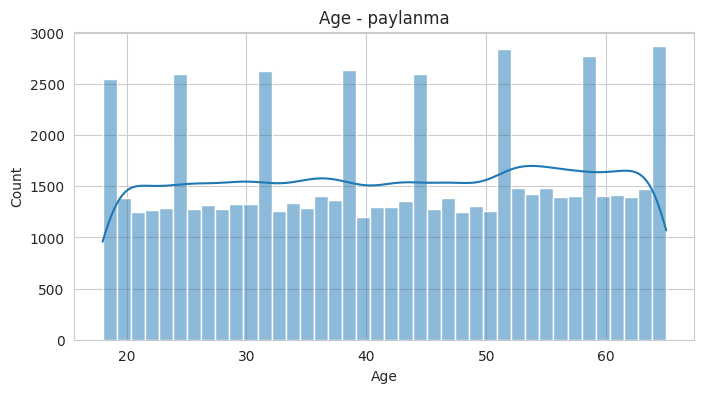

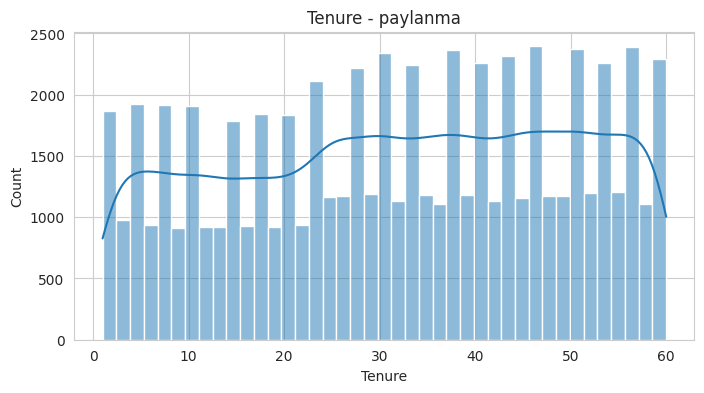

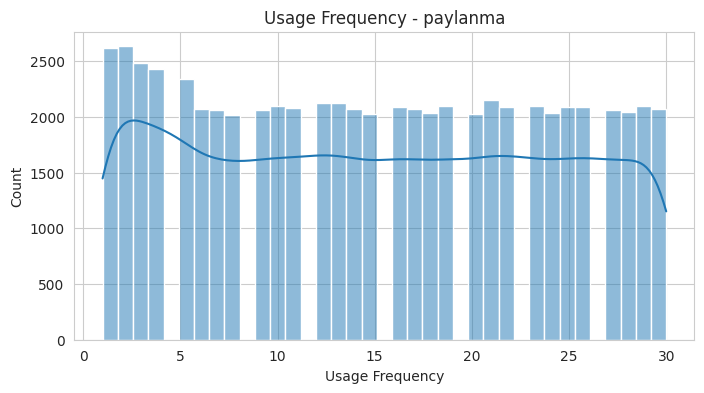

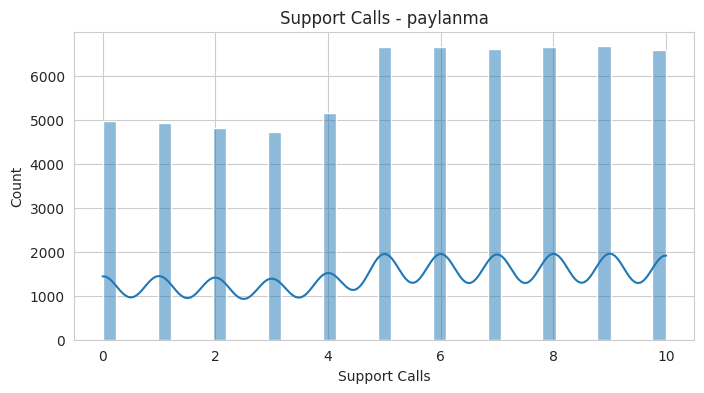

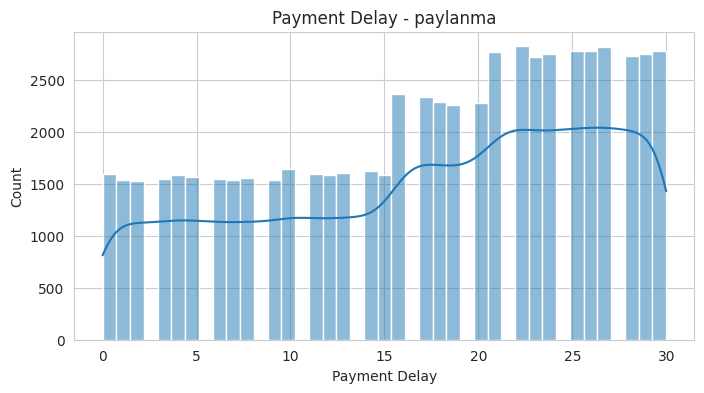

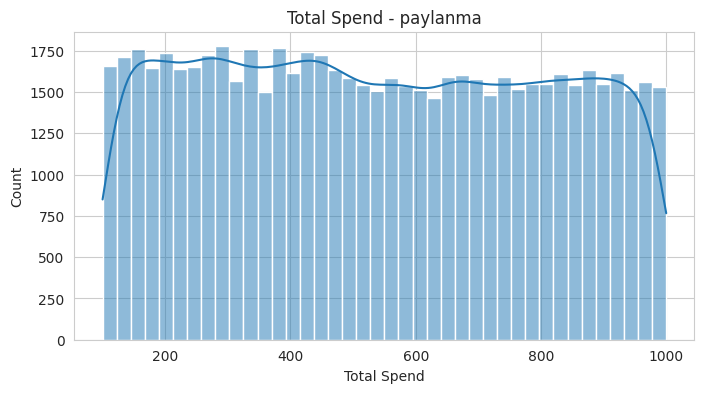

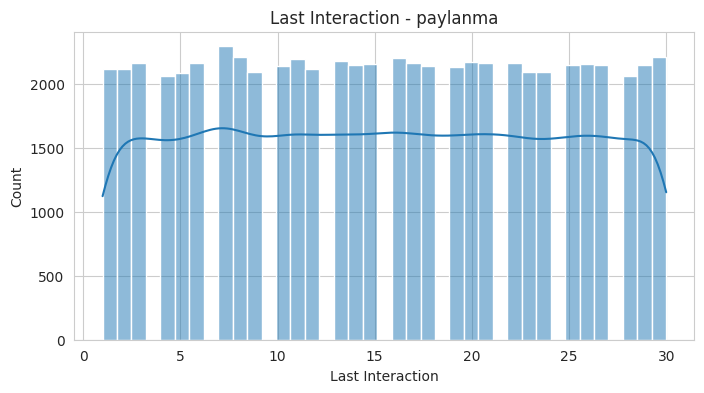

In [18]:
for col in num_cols:
    plt.figure(figsize=(8,4))
    sns.histplot(df[col], kde=True)
    plt.title(f'{col} - paylanma')
    plt.show()

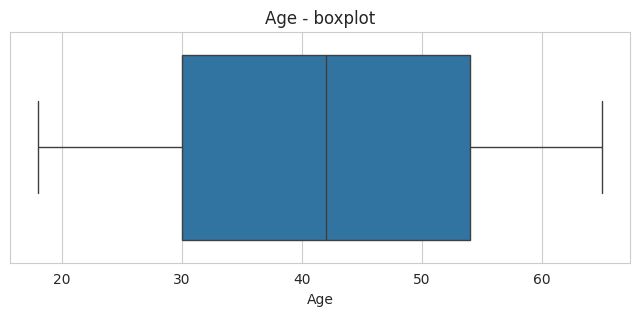

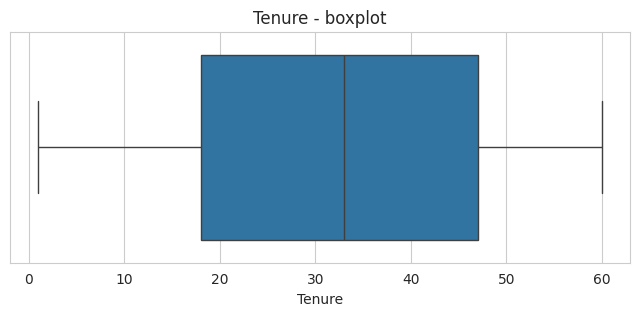

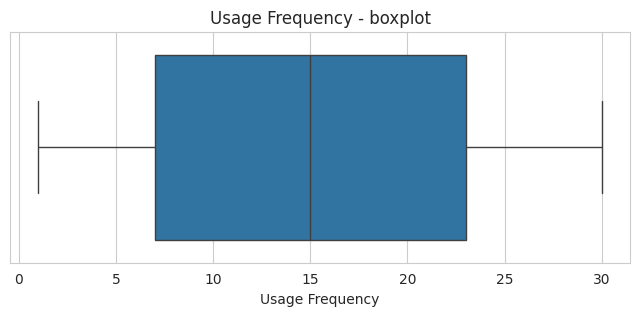

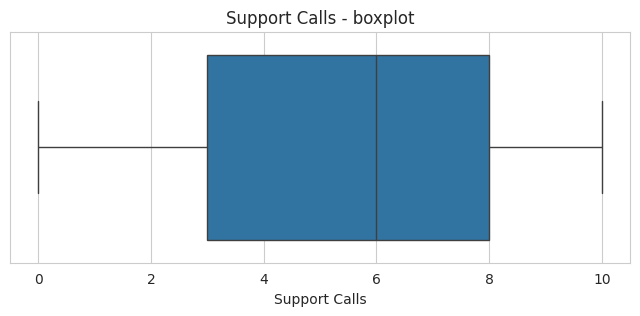

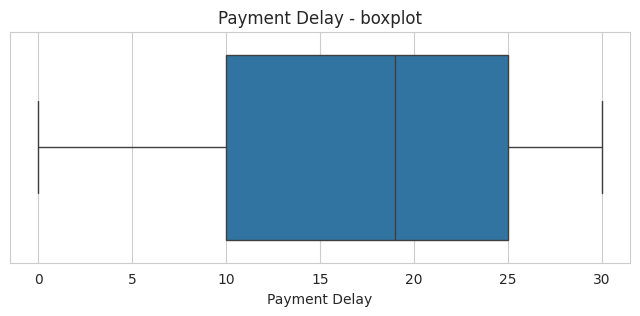

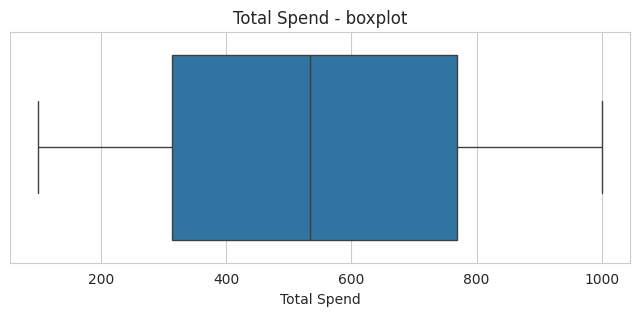

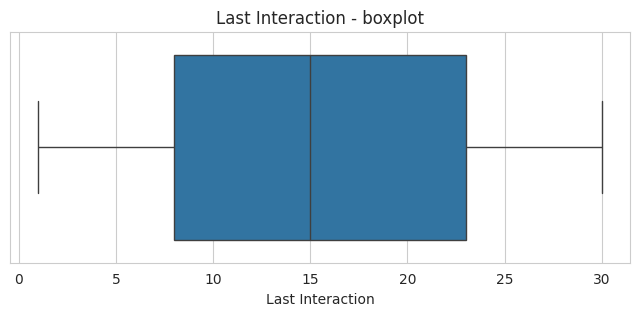

In [19]:
for col in num_cols:
    plt.figure(figsize=(8,3))
    sns.boxplot(x=df[col])
    plt.title(f'{col} - boxplot')
    plt.show()

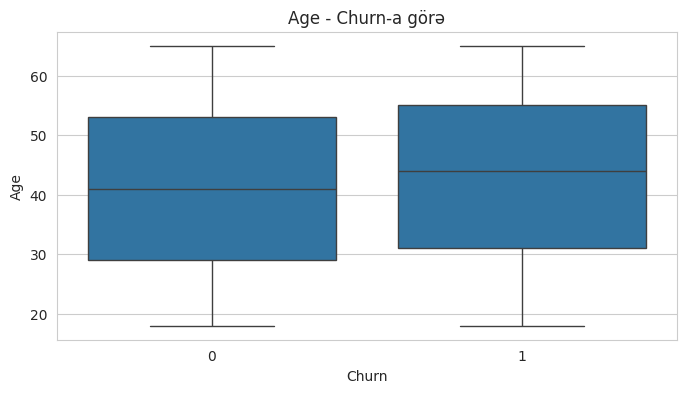

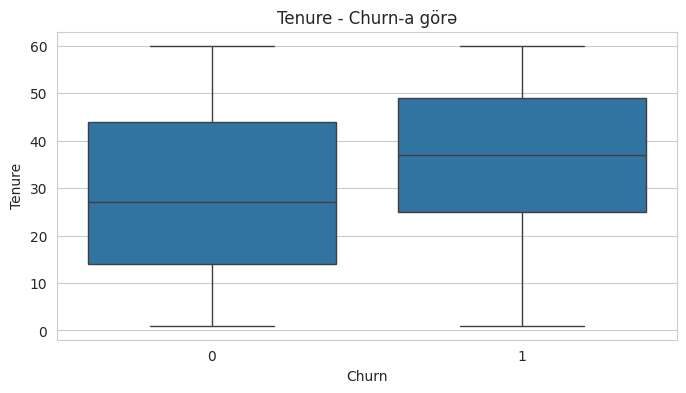

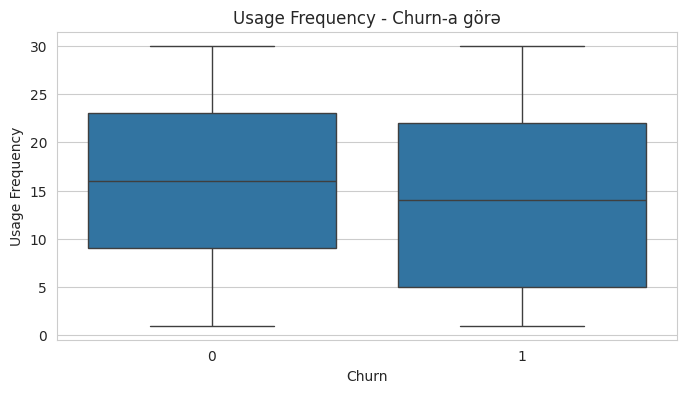

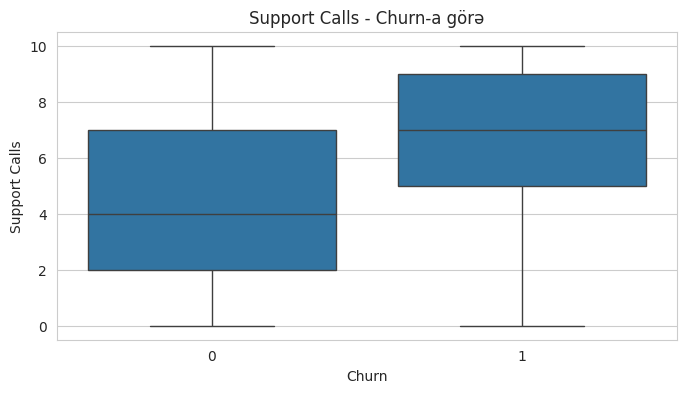

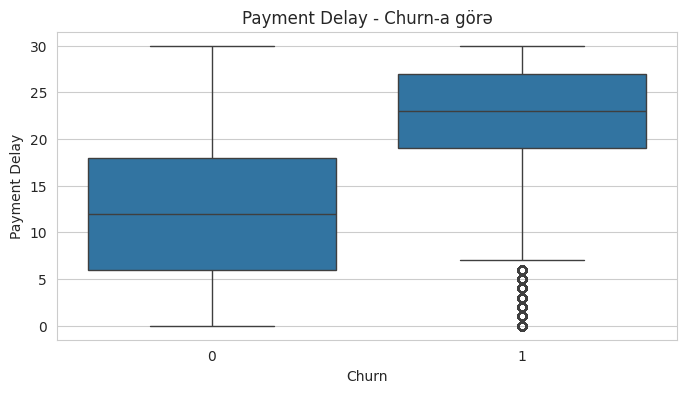

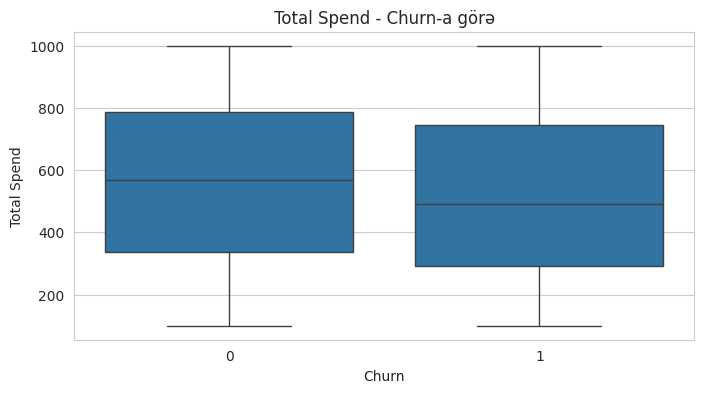

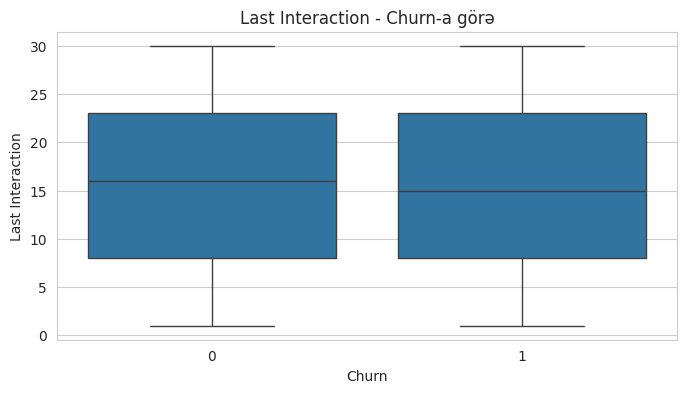

In [20]:
for col in num_cols:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=df['Churn'], y=df[col])
    plt.title(f'{col} - Churn-a görə')
    plt.show()

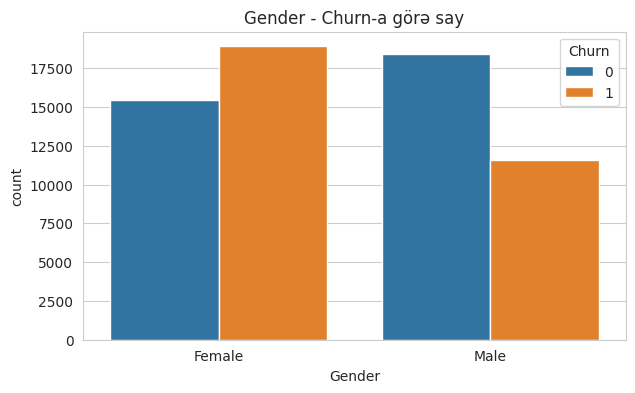

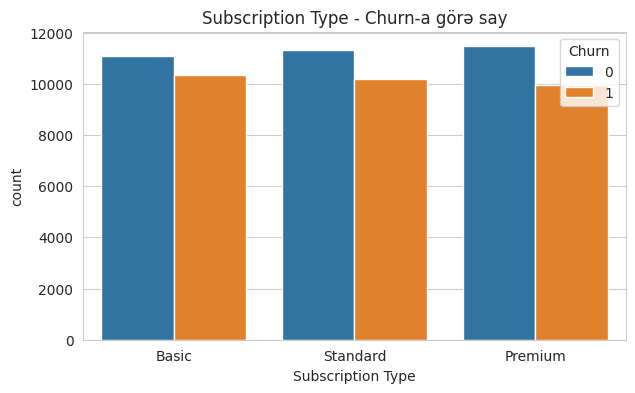

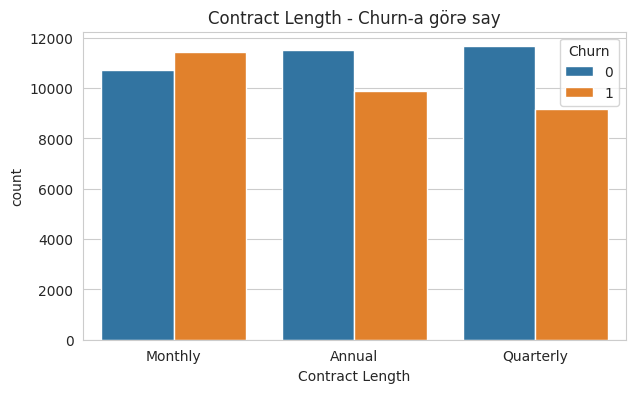

In [21]:
for col in cat_cols:
    plt.figure(figsize=(7,4))
    sns.countplot(x=df[col], hue=df['Churn'])
    plt.title(f'{col} - Churn-a görə say')
    plt.show()

In [22]:
for col in cat_cols:
    print(df.groupby(col)['Churn'].mean().round(3))
    print()

Gender
Female    0.550
Male      0.386
Name: Churn, dtype: float64

Subscription Type
Basic       0.483
Premium     0.465
Standard    0.473
Name: Churn, dtype: float64

Contract Length
Annual       0.462
Monthly      0.516
Quarterly    0.440
Name: Churn, dtype: float64



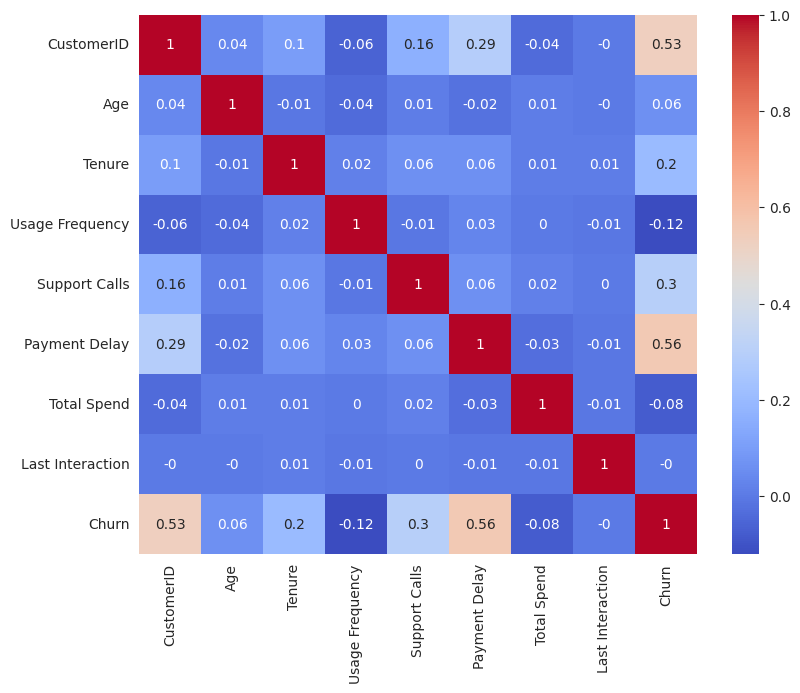

In [23]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9,7))
sns.heatmap(corr.round(2), annot=True, cmap='coolwarm')
plt.show()

In [24]:
corr['Churn'].sort_values(ascending=False)

,Churn
Churn,1.000000
Payment Delay,0.557386
CustomerID,0.529832
Support Calls,0.304631
Tenure,0.195327
Age,0.063457
Last Interaction,-0.002818
Total Spend,-0.078867
Usage Frequency,-0.115098


In [25]:
df.groupby(pd.cut(df['CustomerID'], 6))['Churn'].mean()

,Churn
CustomerID,
"(-63.373, 10729.833]",0.261627
"(10729.833, 21458.667]",0.257899
"(21458.667, 32187.5]",0.254823
"(32187.5, 42916.333]",0.256687
"(42916.333, 53645.167]",0.811073
"(53645.167, 64374.0]",1.000000


In [26]:
df = df.drop('CustomerID', axis=1)
df.shape

(64374, 11)

In [27]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [28]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(51499, 10) (12875, 10)


In [29]:
y_train.value_counts(normalize=True)

,proportion
Churn,
0,0.526321
1,0.473679


In [30]:
X_nums = X_train.select_dtypes(include=np.number).columns
X_cat = X_train.select_dtypes(exclude=np.number).columns
print(list(X_nums))
print(list(X_cat))

['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
['Gender', 'Subscription Type', 'Contract Length']


In [31]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier

In [32]:
X_num_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),
                           ('scaler', StandardScaler())])

X_cat_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                           ('one-hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

transformer = ColumnTransformer([('num', X_num_pipeline, X_nums),
                                 ('cat', X_cat_pipeline, X_cat)])

In [33]:
model = HistGradientBoostingClassifier(random_state=42)

full_pipeline = Pipeline([('preprocessing', transformer),
                          ('estimator', model)])
full_pipeline

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
       'Total Spend', 'Last Interaction'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('one-hot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  Index(['Gender', 'Subscription Type', 'Contract Length'], dtype='object'))])),
                ('estimator', HistGradientBoostingClassifier(random_state=42))])

In [34]:
full_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
       'Total Spend', 'Last Interaction'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('one-hot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  Index(['Gender', 'Subscription Type', 'Contract Length'], dtype='object'))])),
                ('estimator', HistGradientBoostingClassifier(random_state=42))])

In [35]:
print('Train accuracy:', full_pipeline.score(X_train, y_train))
print('Test accuracy :', full_pipeline.score(X_test, y_test))

Train accuracy: 1.0
Test accuracy : 0.9998446601941747


In [36]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_acc = cross_val_score(full_pipeline, X_train, y_train, cv=skf, scoring='accuracy')
cv_f1 = cross_val_score(full_pipeline, X_train, y_train, cv=skf, scoring='f1')
print('CV accuracy:', cv_acc.round(4), cv_acc.mean().round(4))
print('CV f1      :', cv_f1.round(4), cv_f1.mean().round(4))

CV accuracy: [0.9999 0.9993 0.9997 0.9998 0.9999] 0.9997
CV f1      : [0.9999 0.9993 0.9997 0.9998 0.9999] 0.9997


In [37]:
y_test_pred = full_pipeline.predict(X_test)
y_test_proba = full_pipeline.predict_proba(X_test)[:, 1]

In [38]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, roc_auc_score, classification_report
print('accuracy =', round(accuracy_score(y_test, y_test_pred), 4))
print('precision =', round(precision_score(y_test, y_test_pred), 4))
print('recall =', round(recall_score(y_test, y_test_pred), 4))
print('f1 =', round(f1_score(y_test, y_test_pred), 4))
print('roc_auc =', round(roc_auc_score(y_test, y_test_proba), 4))

accuracy = 0.9998
precision = 0.9997
recall = 1.0
f1 = 0.9998
roc_auc = 1.0


In [39]:
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6776
           1       1.00      1.00      1.00      6099

    accuracy                           1.00     12875
   macro avg       1.00      1.00      1.00     12875
weighted avg       1.00      1.00      1.00     12875



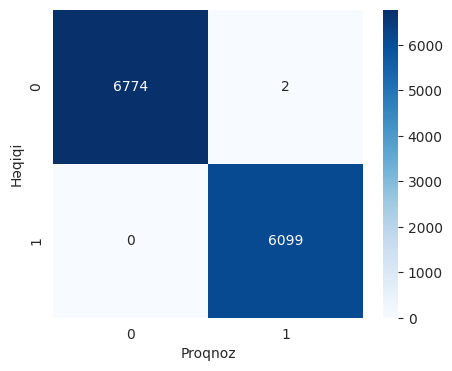

In [40]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Proqnoz')
plt.ylabel('Həqiqi')
plt.show()

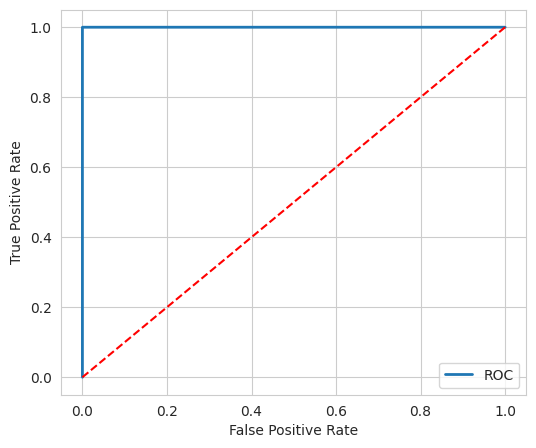

In [41]:
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label='ROC')
plt.plot([0, 1], [0, 1], 'r--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

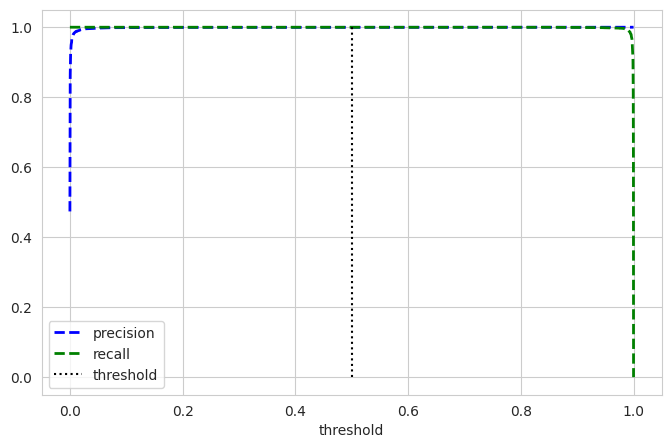

In [42]:
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y_test, y_test_proba)
plt.figure(figsize=(8,5))
plt.plot(thresholds, precisions[:-1], 'b--', label='precision', linewidth=2)
plt.plot(thresholds, recalls[:-1], 'g--', label='recall', linewidth=2)
plt.vlines(0.5, 0, 1.0, 'k', 'dotted', label='threshold')
plt.xlabel('threshold')
plt.legend()
plt.grid(True)
plt.show()

In [43]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(full_pipeline, X_test, y_test, n_repeats=5, random_state=42, scoring='f1')
importance = pd.DataFrame({'Feature': X_test.columns, 'Importance': perm.importances_mean}).sort_values('Importance', ascending=False)
importance

,Feature,Importance
5,Payment Delay,0.325149
4,Support Calls,0.167667
2,Tenure,0.130966
1,Gender,0.084047
3,Usage Frequency,0.073355
8,Total Spend,0.051308
7,Contract Length,0.045678
0,Age,0.039146
6,Subscription Type,0.002577
9,Last Interaction,0.000000


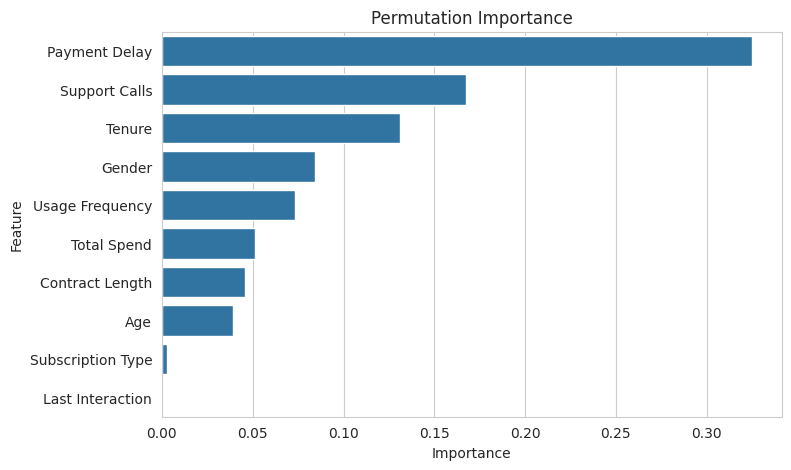

In [44]:
plt.figure(figsize=(8,5))
sns.barplot(data=importance, x='Importance', y='Feature')
plt.title('Permutation Importance')
plt.show()

In [45]:
import joblib
joblib.dump(full_pipeline, 'churn_pipeline.pkl')
loaded = joblib.load('churn_pipeline.pkl')
print(np.array_equal(loaded.predict(X_test), y_test_pred))

True


In [46]:
new_customer = pd.DataFrame([{'Age': 30, 'Gender': 'Female', 'Tenure': 12, 'Usage Frequency': 5, 'Support Calls': 8,
                              'Payment Delay': 25, 'Subscription Type': 'Basic', 'Contract Length': 'Monthly',
                              'Total Spend': 400, 'Last Interaction': 10}])
print('Churn ehtimalı:', round(full_pipeline.predict_proba(new_customer)[0, 1], 4))
print('Proqnoz:', full_pipeline.predict(new_customer)[0])

Churn ehtimalı: 0.9993
Proqnoz: 1


Test nəticələri çox yüksəkdir (accuracy ≈ 0.9998, F1 ≈ 0.9998, ROC-AUC ≈ 1.0; 12 875 test sətrində cəmi 2 səhv), lakin bu, real müştəri davranışını əks etdirmir. Səbəbi data sızması (leakage) və ya overfitting deyil — korrelyasiyalı `CustomerID` çıxarılıb və cross-validation nəticəsi (0.9997) test ilə üst-üstə düşür. Sadəcə dataset sintetikdir və churn demək olar ki, dəqiq qaydalarla (*Payment Delay, Support Calls, Tenure, Gender, Usage Frequency*) müəyyən olunur. Real datada belə göstərici gözləmək olmaz; bu notebook yalnız modelləşdirmə və qiymətləndirmə prosesini göstərir.